MD# 03 · What is associated with default?

**Northvale Credit is a fictional lender; the data is public Lending Club loans.**

Question: before modelling, which application fields separate defaulters from good loans on the training window (2012-2014)? These are associations, not causes: Lending Club approved and priced these borrowers using some of the same fields. Tables come from `src/northvale/eda.py`.

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Image, display

from northvale import config as C

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 20)
m = json.loads(C.METRICS.read_text())


def fig(name, width=900):
    display(Image(filename=str(C.FIGURES / f"{name}.png"), width=width))

In [2]:
from northvale import eda
from northvale import features as F

df = F.sample()
print(f"{len(df):,} loans, {df.shape[1]} columns in memory")

589,249 loans, 85 columns in memory


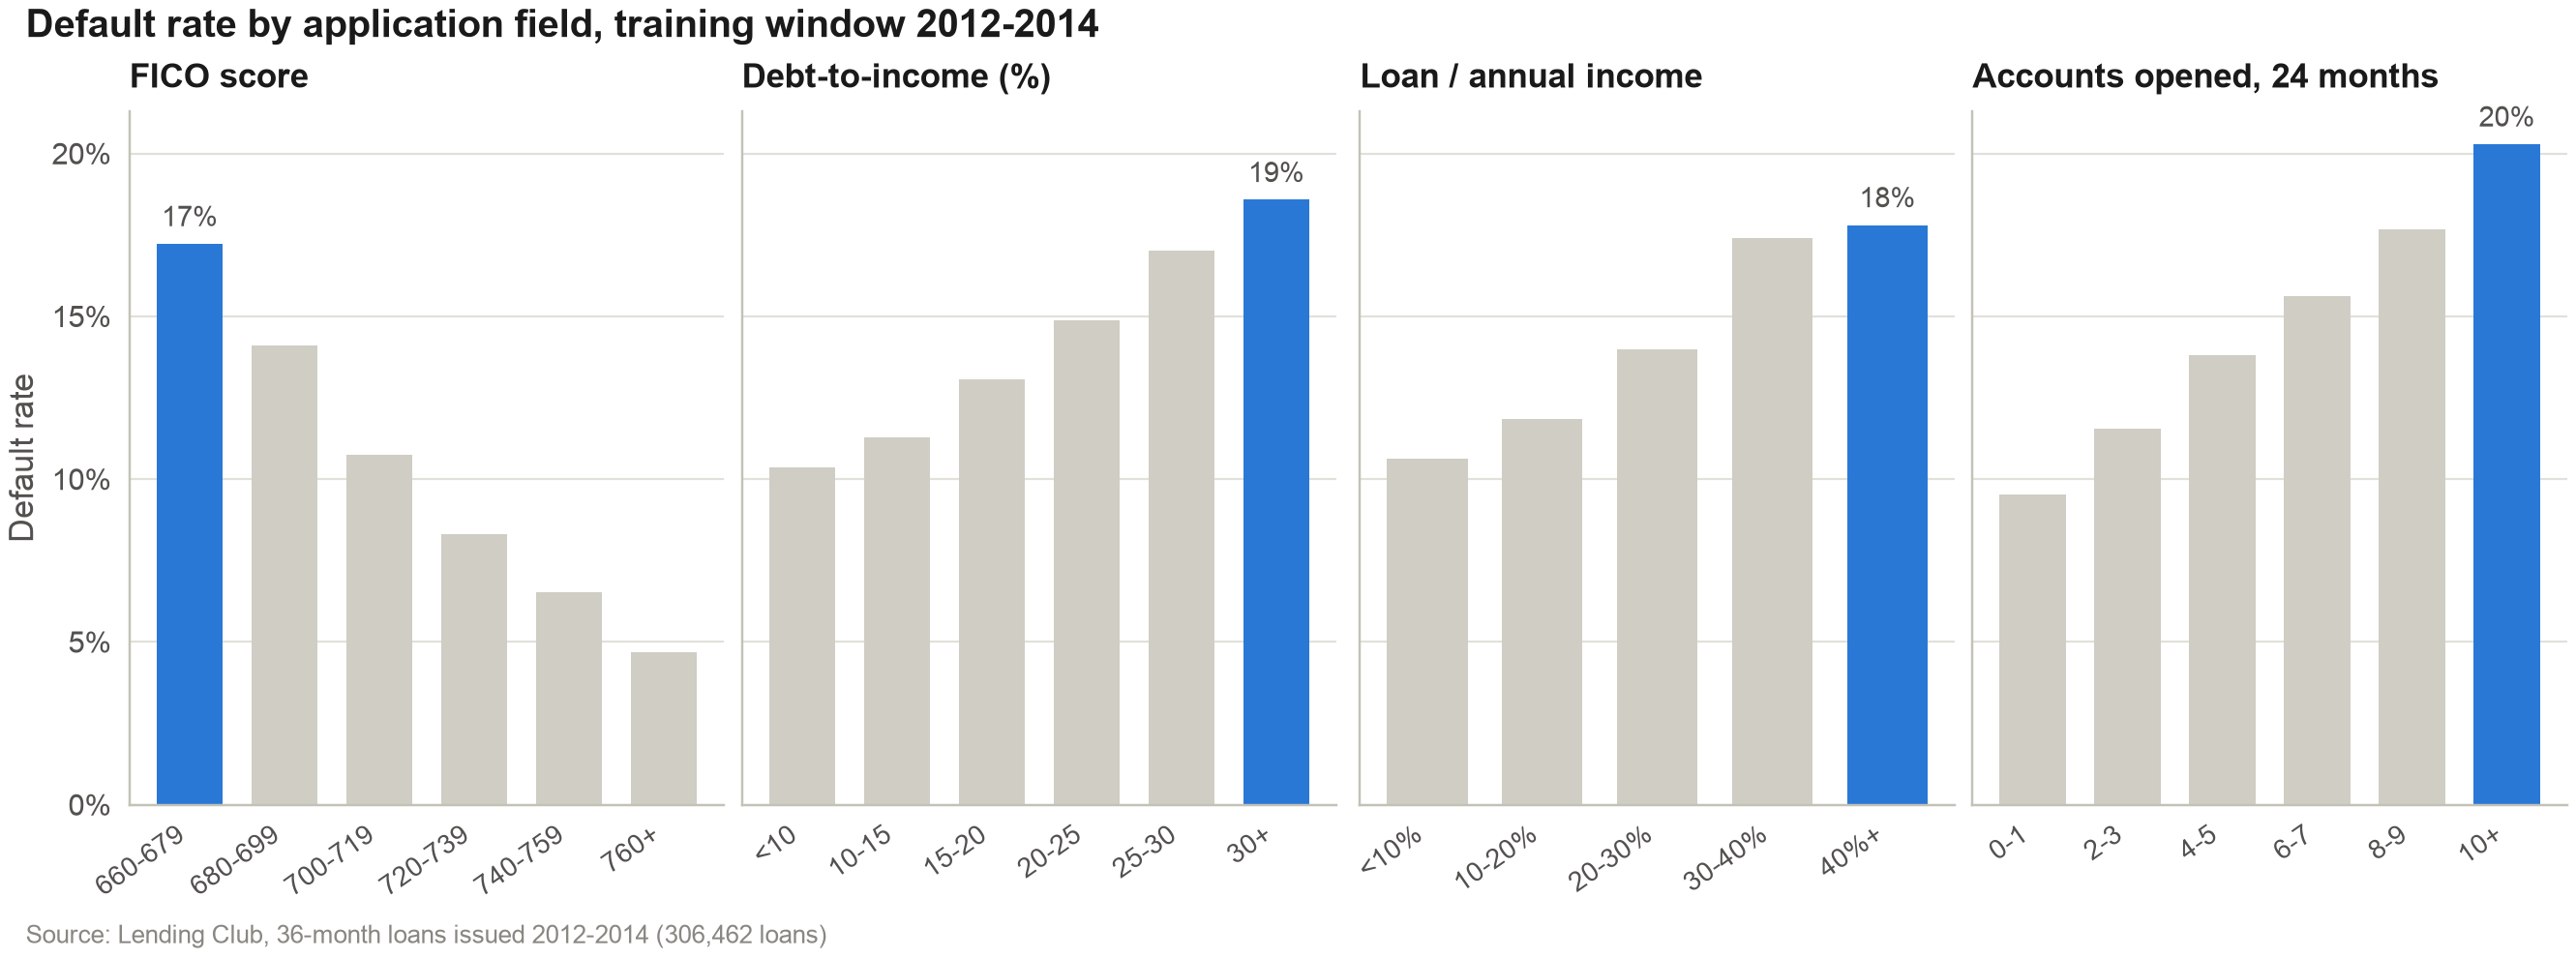

In [3]:
fig("eda_default_drivers")

MD## 1. Credit score and income

In [4]:
display(eda.rate_table(df, "fico"))
display(eda.rate_table(df, "annual_inc"))

,fico,n_loans,default_rate,share
0,660-679,106489,0.1722,0.3475
1,680-699,87049,0.1410,0.2840
2,700-719,56498,0.1074,0.1844
3,720-739,28195,0.0830,0.0920
4,740-759,13594,0.0652,0.0444
5,760+,14637,0.0469,0.0478


,annual_inc,n_loans,default_rate,share
0,<40k,58663,0.1854,0.1914
1,40-60k,86511,0.1459,0.2823
2,60-80k,66804,0.1231,0.2180
3,80-100k,40741,0.1013,0.1329
4,100-150k,38139,0.0883,0.1244
5,150k+,15604,0.0886,0.0509


MD## 2. Indebtedness and appetite for new credit

In [5]:
display(eda.rate_table(df, "dti"))
display(eda.rate_table(df, "loan_to_income"))
display(eda.rate_table(df, "acc_open_past_24mths"))

,dti,n_loans,default_rate,share
0,<10,61371,0.1035,0.2003
1,10-15,67638,0.1129,0.2207
2,15-20,68327,0.1306,0.2230
3,20-25,54708,0.1487,0.1785
4,25-30,35909,0.1701,0.1172
5,30+,18509,0.1858,0.0604


,loan_to_income,n_loans,default_rate,share
0,<10%,55491,0.1064,0.1811
1,10-20%,111785,0.1185,0.3648
2,20-30%,83167,0.1399,0.2714
3,30-40%,42214,0.1741,0.1377
4,40%+,13805,0.1781,0.0450


,acc_open_past_24mths,n_loans,default_rate,share
0,0-1,47219,0.0952,0.1541
1,2-3,93249,0.1155,0.3043
2,4-5,80682,0.1380,0.2633
3,6-7,45970,0.1562,0.1500
4,8-9,20392,0.1767,0.0665
5,10+,12925,0.2029,0.0422
6,missing,6025,0.1320,0.0197


MD## 3. Purpose and employment

Small-business and moving loans default most; car and credit-card refinancing least. A missing employment length is itself a risk signal, so missing values are kept as information rather than imputed.

In [6]:
display(eda.rate_table(df, "purpose"))
display(eda.rate_table(df, "emp_length_years"))

,purpose,n_loans,default_rate,share
0,car,3146,0.1074,0.0103
1,credit_card,75344,0.1123,0.2459
2,home_improvement,16408,0.1151,0.0535
3,major_purchase,5858,0.1185,0.0191
4,debt_consolidation,176697,0.1377,0.5766
5,vacation,1920,0.1542,0.0063
6,other,18035,0.1573,0.0588
7,medical,3236,0.1669,0.0106
8,moving,2078,0.1867,0.0068
9,small_business,3740,0.2222,0.0122


,emp_length_years,n_loans,default_rate,share
0,<1,23718,0.1412,0.0774
1,1-2,47428,0.1337,0.1548
2,3-5,62786,0.1319,0.2049
3,6-9,61303,0.1332,0.2000
4,10+,94857,0.1191,0.3095
5,missing,16370,0.1930,0.0534


MD**Answer.** FICO is the strongest single driver, followed by income, loan size relative to income, debt-to-income and the number of recently opened accounts. Each relationship is monotonic, which supports monotonic bins in the scorecard (notebook 04).